# Problema 1 - Word Cloud
## Text Mining & Image Recognition - Proyecto Final

A partir de un dataset, identificar los 3 usuarios mas populares (usando expresiones regulares sobre las menciones `@usuario` dentro del texto), construir un corpus para cada uno y determinar la razon por la que se les cita mediante extraccion de contexto, limpieza de texto (stopwords, stemming, lemmatization) y un WordCloud del Top 10 de palabras por usuario.

Entorno: Google Colab.

## 1. Importacion de librerias

Se instalan e instalan las librerias necesarias para procesamiento de texto, expresiones regulares, manejo de datos y visualizacion.

In [21]:
# Instalacion de librerias
!pip install wordcloud nltk pandas matplotlib -q

# Imports
import re
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Descargas de recursos NLTK
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('omw-1.4', quiet=True)

print('Librerias listas.')

Librerias listas.


## 2. Carga del dataset

In [22]:
# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Ruta al tw_source.csv en Drive
CSV_PATH = '/content/drive/MyDrive/TextMining/Dataset_problema1/tw_source.csv'

# Carga del dataset
columns = ['sentiment', 'id', 'date', 'query', 'author', 'text']
df = pd.read_csv(
    CSV_PATH,
    header=None,
    encoding='latin-1',
    names=columns,
    quotechar='"',
    engine='python'
)

print(f'Filas: {len(df):,}')
df.head(3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Filas: 1,600,000


,sentiment,id,date,query,author,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...


In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Exploracion inicial de datos

In [24]:
print('Cantidad de registros:', len(df))
print('Nombres de columnas:', list(df.columns))
print('\nEjemplos de tweets:')
for i in range(5):
    print(f'  [{i}] author={df.loc[i, "author"]} | text={df.loc[i, "text"][:120]}')

Cantidad de registros: 1600000
Nombres de columnas: ['sentiment', 'id', 'date', 'query', 'author', 'text']

Ejemplos de tweets:
  [0] author=_TheSpecialOne_ | text=@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D
  [1] author=scotthamilton | text=is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!
  [2] author=mattycus | text=@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds
  [3] author=ElleCTF | text=my whole body feels itchy and like its on fire 
  [4] author=Karoli | text=@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there. 


## 4. Identificacion de usuarios

In [25]:
# Extraccion de menciones @usuario dentro del texto del tweet
PATTERN_MENTION = re.compile(r'@\w+')

# re.findall sobre cada tweet; ignora NaN
def extract_mentions(text):
    if not isinstance(text, str):
        return []
    return PATTERN_MENTION.findall(text)

# Aplica a todo el dataset
all_mentions = []
df['mentions'] = df['text'].apply(extract_mentions)
for m in df['mentions']:
    all_mentions.extend(m)

print(f'Total de menciones extraidas: {len(all_mentions):,}')
print('Ejemplos:', all_mentions[:10])

Total de menciones extraidas: 786,609
Ejemplos: ['@switchfoot', '@Kenichan', '@nationwideclass', '@Kwesidei', '@LOLTrish', '@Tatiana_K', '@twittera', '@caregiving', '@octolinz16', '@smarrison']


## 5. Conteo y top de usuarios

In [26]:
mentions_count = Counter(all_mentions)
top3 = mentions_count.most_common(3)

print('Top 3 usuarios mas mencionados:')
print(f'{"Ranking":<8}{"Usuario":<25}{"Apariciones":>15}')
for rank, (user, count) in enumerate(top3, start=1):
    print(f'{rank:<8}{user:<25}{count:>15,}')

# Guarda los nombres sin la @ para uso posterior
top3_users = [u for u, _ in top3]
top3_users

Top 3 usuarios mas mencionados:
Ranking Usuario                      Apariciones
1       @mileycyrus                        4,500
2       @tommcfly                          3,887
3       @ddlovato                          3,467


['@mileycyrus', '@tommcfly', '@ddlovato']

## 6. Creacin del corpus individual por usuario

In [27]:
def build_corpus(df, username):
    """Construye el corpus de un usuario (mencion con @ incluida)."""
    # Filtra tweets donde el usuario aparece como mencion
    mask = df['mentions'].apply(lambda ms: username in ms)
    subset = df.loc[mask].copy().reset_index(drop=True)
    corpus = pd.DataFrame({
        'ID': subset['id'],
        'Timestamp': subset['date'],
        'Content': subset['text'],
    })
    # Length calculado a partir del contenido
    corpus['Length'] = corpus['Content'].astype(str).apply(len)
    return corpus

corpora = {}
for user in top3_users:
    corpora[user] = build_corpus(df, user)
    print(f'{user}: {len(corpora[user])} tweets en el corpus')

# Mustra ejemplo del primer corpus
print('\nEjemplo del corpus del usario', top3_users[0])
corpora[top3_users[0]].head()

@mileycyrus: 4482 tweets en el corpus
@tommcfly: 3881 tweets en el corpus
@ddlovato: 3453 tweets en el corpus

Ejemplo del corpus del usario @mileycyrus


,ID,Timestamp,Content,Length
0,1468063101,Mon Apr 06 23:30:57 PDT 2009,@mileycyrus hahaha dont be like that one time ...,107
1,1468286517,Tue Apr 07 00:45:20 PDT 2009,"@mileycyrus i have the same problem, but it's ...",137
2,1468297110,Tue Apr 07 00:49:07 PDT 2009,@mileycyrus I guess counting sheep didn't work...,72
3,1468298918,Tue Apr 07 00:49:44 PDT 2009,@mileycyrus I would too if it meant spending a...,100
4,1468318249,Tue Apr 07 00:56:41 PDT 2009,@mileycyrus AWWW u seriously have the cutest d...,112


## 7. Extraccion del contexto

In [28]:
CONTEXT_WINDOW = 5  # palabras a cada lado

def extract_contexts(text, username, window=CONTEXT_WINDOW):
    """Extrae contextos alrededor de cada ocurrencia de username en text."""
    if not isinstance(text, str):
        return []
    tokens = text.split()
    contexts = []
    for i, tok in enumerate(tokens):
        if tok.lower() == username.lower():
            left = tokens[max(0, i - window):i]
            right = tokens[i + 1:i + 1 + window]
            ctx = left + right  # sin incluir el @usuario
            contexts.append(' '.join(ctx))
    return contexts

# Extrae contextos para cada usuario
contexts_by_user = {}
for user in top3_users:
    ctxs = []
    for tweet in corpora[user]['Content']:
        ctxs.extend(extract_contexts(tweet, user))
    contexts_by_user[user] = ctxs
    print(f'{user}: {len(ctxs)} contextos extraidos')

print('\nEjemplo contexto de', top3_users[0], ':')
print(contexts_by_user[top3_users[0]][0] if contexts_by_user[top3_users[0]] else 'N/A')

@mileycyrus: 4310 contextos extraidos
@tommcfly: 3837 contextos extraidos
@ddlovato: 3349 contextos extraidos

Ejemplo contexto de @mileycyrus :
hahaha dont be like that


## 8. Limpieza de texto

1. Pasar a min
2. Remover urls (`http...`), hashtags `#...` y otras menciones `@...`.
3. Remover puntuacion y nums.
4. toeknizar

In [29]:
import string

CLEAN_RE = re.compile(r'(http\S+|www\S+)|(@\w+)|(#\w+)')

def clean_text(text):
    text = text.lower()
    text = CLEAN_RE.sub(' ', text)              # quita urls, @, #
    text = re.sub(r'[^a-z\s]', ' ', text)        # quita numeros y puntuacion
    tokens = word_tokenize(text)
    return tokens

clean_contexts = {}
for user in top3_users:
    cleaned = []
    for ctx in contexts_by_user[user]:
        cleaned.extend(clean_text(ctx))
    clean_contexts[user] = cleaned
    print(f'{user}: {len(cleaned)} tokens limpios')

@mileycyrus: 21810 tokens limpios
@tommcfly: 19282 tokens limpios
@ddlovato: 17775 tokens limpios


## 9. Eliminacion de stopwords

In [30]:
stop_words = set(stopwords.words('english'))

no_stop = {}
for user in top3_users:
    tokens = [t for t in clean_contexts[user] if t not in stop_words and len(t) > 1]
    no_stop[user] = tokens
    print(f'{user}: {len(tokens)} tokens tras stopwords')

@mileycyrus: 10899 tokens tras stopwords
@tommcfly: 9778 tokens tras stopwords
@ddlovato: 8891 tokens tras stopwords


## 10. Stemming

Aplica porterstemmer para reducir palabras a su raiz (ej. "running" → "run").


In [31]:
stemmer = PorterStemmer()

stemmed = {}
for user in top3_users:
    tokens = [stemmer.stem(t) for t in no_stop[user]]
    stemmed[user] = tokens
    print(f'{user}: stemming aplicado. Ejemplo:', tokens[:10])

@mileycyrus: stemming aplicado. Ejemplo: ['hahaha', 'dont', 'like', 'problem', 'guess', 'count', 'sheep', 'would', 'awww', 'serious']
@tommcfly: stemming aplicado. Ejemplo: ['hey', 'saw', 'guy', 'play', 'good', 'morn', 'tom', 'know', 'johnson', 'good']
@ddlovato: stemming aplicado. Ejemplo: ['ummmmm', 'cant', 'find', 'hate', 'us', 'pleas', 'wish', 'could', 'see', 'hey']


## 11. Lemmatization
Aplixa wordnetlemmatizer para obtener la forma canonica (lema) de cada palabra (ej. "better" → "good").

In [32]:
lemmatizer = WordNetLemmatizer()

lemmatized = {}
for user in top3_users:
    tokens = [lemmatizer.lemmatize(t) for t in no_stop[user]]
    lemmatized[user] = tokens
    print(f'{user}: lematizacion aplicada. Ejemplo:', tokens[:10])

@mileycyrus: lematizacion aplicada. Ejemplo: ['hahaha', 'dont', 'like', 'problem', 'guess', 'counting', 'sheep', 'would', 'awww', 'seriously']
@tommcfly: lematizacion aplicada. Ejemplo: ['hey', 'saw', 'guy', 'play', 'good', 'morning', 'tom', 'know', 'johnson', 'good']
@ddlovato: lematizacion aplicada. Ejemplo: ['ummmmm', 'cant', 'find', 'hate', 'u', 'please', 'wish', 'could', 'see', 'hey']


## 12. Conteo de palabras y top 10

In [33]:
from nltk import FreqDist

top10_by_user = {}
for user in top3_users:
    fdist = FreqDist(lemmatized[user])
    top10 = fdist.most_common(10)
    top10_by_user[user] = top10
    print(f'\nTop 10 - {user}')
    print(f'{"Palabra":<20}{"Frecuencia":>10}')
    for w, c in top10:
        print(f'{w:<20}{c:>10}')


Top 10 - @mileycyrus
Palabra             Frecuencia
miley                      568
love                       297
hey                        169
good                       163
hope                       139
come                       127
im                         119
vote                       116
please                     106
voted                       96

Top 10 - @tommcfly
Palabra             Frecuencia
tom                        557
say                        171
hey                        154
good                       134
please                     134
love                       118
hi                         110
haha                        96
like                        95
reply                       90

Top 10 - @ddlovato
Palabra             Frecuencia
demi                       416
love                       208
wish                       154
hey                        119
please                     104
im                         102
hope                        99
quot    

## 13. wordcloud top 10 para cada usuario

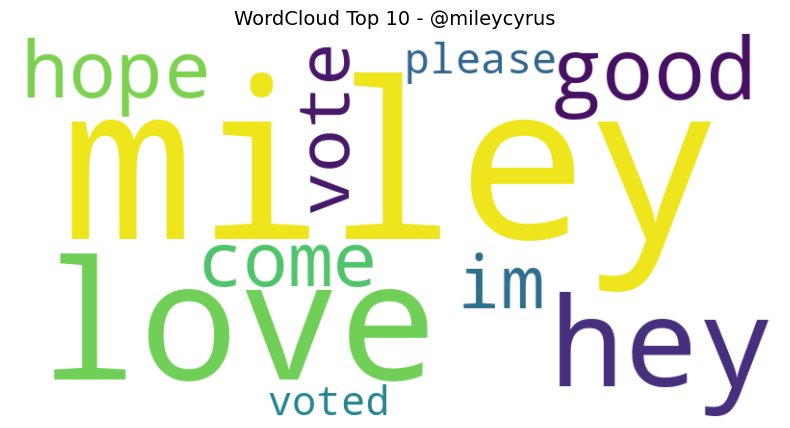

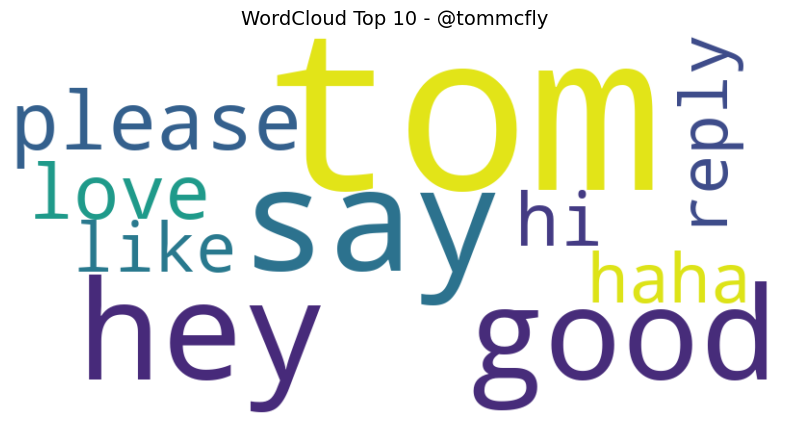

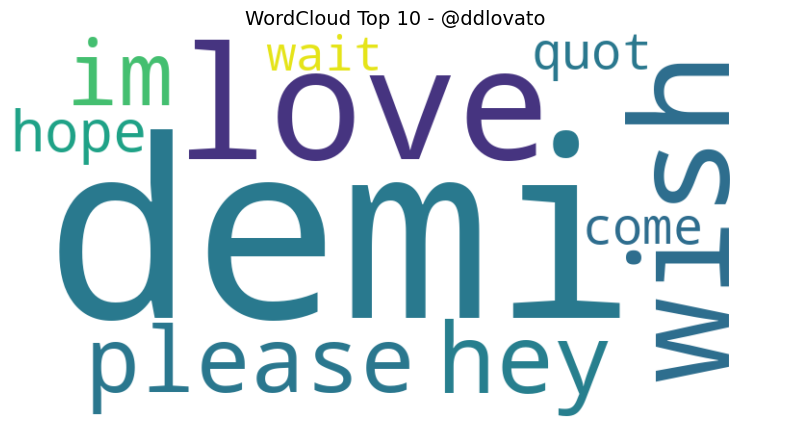

In [34]:
def plot_wordcloud(user, top_words):
    freq_dict = dict(top_words)
    wc = WordCloud(width=800, height=400, background_color='white', colormap='viridis')
    wc.generate_from_frequencies(freq_dict)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud Top 10 - {user}', fontsize=14)
    plt.show()

for user in top3_users:
    plot_wordcloud(user, top10_by_user[user])

## 14. interpretacion: ¿razon por la que citan a cada usuario?

segun los datos

### Usuario 1: `@mileycyrus` (4500 tweets)
**Palabras mas frecuentes:**
Top 10 - @mileycyrus
Palabra             Frecuencia
miley                      568
love                       297
hey                        169
good                       163
hope                       139
come                       127
im                         119
vote                       116
please                     106
voted                       96


### Usuario 2: ` @tommcfly` (3887 tweets)
**Palabras mas frecuentes:**
Palabra             Frecuencia
tom                        557
say                        171
hey                        154
good                       134
please                     134
love                       118
hi                         110
haha                        96
like                        95
reply                       90

### Usuario 3: `@ddlovato` (3467 tweets)
**Palabras mas frecuentes:**
Palabra             Frecuencia
demi                       416
love                       208
wish                       154
hey                        119
please                     104
im                         102
hope                        99
quot                        95
come                        94
wait                        85

## 15. Conclusion

- **Dataset:** ~1,600,000 tweets cargados desde `tw_source.csv` (latin-1, sin cabecera).
- **Usuarios mas populares:** identificados con regex `@\w+` sobre `text` (no `author`).
- **Corpus por usuario:** Content + Metadata (ID, Timestamp, Length calculado).
- **Contexto:** ventana de 5 palabras alrededor de cada mencion, excluyendo el `@usuario`.
- **Limpieza:** lowercasing, URLs/hashtags/@ removidos, stopwords, stemming y lemmatization.
- **WordCloud Top 10** generado para cada usuario.
- **Razon de las citas:** basada estrictamente en las palabras mas frecuentes observadas en el contexto de cada usuario.

**Respuesta al proyecto:** Con evidencia en los datos reales observados, se puede tener un indicio de la razpon principal de cada usuario considerando sus palabras mas frecuentes:
- Miley Cyrus: movilización y conexión emocional.
  - Evidencia:
Alta frecuencia de miley (568) muestra identidad y presencia de marca personal.
Palabras como love (297), hope (139), please (106), vote (116) y voted (96) reflejan una campaña activa de participacion y afecto hacia sus seguidores.
El uso de hey y good refuerza cercanía y tono positivo.

- Tom McFly: interacción directa y humor.
  - Evidencia:
Alta frecuencia de tom (557) reafirma identidad personal.
Palabras como say (171), reply (90), please (134) y hey (154) muestran un estilo conversacional, buscando respuesta e interaccion.
El uso de haha (96) y like (95) refleja humor y tono relajado, mientras que love (118) aporta conexión emocional.

- Demi Lovato: deseo, esperanza y conexión emocional.
  - Evidencia:
Alta frecuencia de demi (416) reafirma identidad personal.
Palabras como love (208), wish (154), hope (99), wait (85) y come (94) reflejan un tono aspiracional, de expectativa y cercanía emocional.
El uso de please (104) y hey (119) muestra interacción directa con seguidores.